# Deep Learning Laboratory - Experiment 10

## GAN and Quantitative Evaluation

This is a standalone notebook for this lab section. Run the setup and dataset cells first, then run the experiment cell and its output check. Use a Colab GPU runtime for the image and generative-model experiments when available.


## Step 1 — Install the Additional Colab Packages

Wait until installation completes before the next cell starts.

In [ ]:
%pip -q install -U datasets "transformers<5" sentencepiece accelerate torchmetrics torch-fidelity ucimlrepo tabulate


## Step 2 — Verify the Runtime

This cell records the Python, TensorFlow, and PyTorch versions and enables safe TensorFlow GPU memory growth.

In [ ]:
from pathlib import Path
import platform
import tensorflow as tf
import torch

project_root = Path("/content/Deeplearning")
project_root.mkdir(parents=True, exist_ok=True)
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
print(f"Python: {platform.python_version()}")
print(f"TensorFlow: {tf.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Project root: {project_root}")


Python: 3.13.15
TensorFlow: 2.20.0
PyTorch: 2.11.0+cu128
CUDA available: True
Project root: /content/Deeplearning


## Step 3 — Import Every Required Dataset

This cell creates visible files under `/content/Deeplearning/datasets` and prints a manifest that can be shown to the staff.

- MNIST, Iris, CIFAR-10, Dogs vs. Cats, Airline Passengers, and Tiny Shakespeare are downloaded as complete or balanced lab-ready files.
- MS COCO, CelebA, and LSUN Bedrooms are the genuine named datasets, streamed as practical subsets for Colab.
- No synthetic replacement dataset is used.

In [ ]:
from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from datasets import load_dataset
from sklearn.datasets import load_iris


root = Path("/content/Deeplearning") if Path("/content").exists() else Path(__file__).resolve().parent
dataset_dir = root / "datasets"
output_dir = root / "outputs"
dataset_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)


def balanced_indices(labels, per_class, seed):
    labels = np.asarray(labels).reshape(-1)
    indices = np.concatenate([np.flatnonzero(labels == class_index)[:per_class] for class_index in np.unique(labels)])
    rng = np.random.default_rng(seed)
    rng.shuffle(indices)
    return indices


def save_image_stream(dataset_name, split, destination, count, size, config=None):
    destination.mkdir(parents=True, exist_ok=True)
    existing = sorted(destination.glob("*.jpg"))
    if len(existing) >= count:
        return len(existing)
    arguments = {
        "path": dataset_name,
        "split": split,
        "streaming": True,
    }
    if config is not None:
        arguments["name"] = config
    stream = load_dataset(**arguments)
    saved = 0
    for row in stream.take(count):
        image = row["image"].convert("RGB")
        image = image.resize((size, size), Image.Resampling.LANCZOS)
        image.save(destination / f"image_{saved:04d}.jpg", quality=92)
        saved += 1
    if saved < count:
        raise RuntimeError(f"Only {saved} images were available from {dataset_name}")
    return saved


(mnist_x_train, mnist_y_train), (mnist_x_test, mnist_y_test) = tf.keras.datasets.mnist.load_data()
mnist_train_indices = balanced_indices(mnist_y_train, 1000, 42)
mnist_test_indices = balanced_indices(mnist_y_test, 200, 42)
np.savez_compressed(
    dataset_dir / "mnist_lab.npz",
    x_train=mnist_x_train[mnist_train_indices],
    y_train=mnist_y_train[mnist_train_indices],
    x_test=mnist_x_test[mnist_test_indices],
    y_test=mnist_y_test[mnist_test_indices],
)

try:
    from ucimlrepo import fetch_ucirepo

    iris_repository = fetch_ucirepo(id=53)
    iris_features = iris_repository.data.features.copy()
    iris_features.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
    iris_target = iris_repository.data.targets.iloc[:, 0].astype(str)
    iris_target = iris_target.str.replace("Iris-", "", regex=False).str.replace("Iris ", "", regex=False).str.lower()
    iris = iris_features.copy()
    iris["species"] = iris_target.to_numpy()
    iris_source = "UCI Machine Learning Repository dataset 53"
except Exception:
    iris_bundle = load_iris(as_frame=True)
    iris = iris_bundle.data.copy()
    iris.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
    iris["species"] = pd.Series(iris_bundle.target).map(dict(enumerate(iris_bundle.target_names)))
    iris_source = "scikit-learn packaged Iris fallback"
iris.to_csv(dataset_dir / "iris.csv", index=False)

(cifar_x_train, cifar_y_train), (cifar_x_test, cifar_y_test) = tf.keras.datasets.cifar10.load_data()
cifar_train_indices = balanced_indices(cifar_y_train, 800, 42)
cifar_test_indices = balanced_indices(cifar_y_test, 200, 42)
np.savez_compressed(
    dataset_dir / "cifar10_lab.npz",
    x_train=cifar_x_train[cifar_train_indices],
    y_train=cifar_y_train[cifar_train_indices].reshape(-1),
    x_test=cifar_x_test[cifar_test_indices],
    y_test=cifar_y_test[cifar_test_indices].reshape(-1),
)

def build_cats_and_dogs_filtered(destination, image_size=160, seed=42):
    """Rebuild the classic 'cats_and_dogs_filtered' train/validation layout.

    The original tutorial archive at
    https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip
    now returns HTTP 403 (Google retired the mledu-datasets bucket), so the
    same 3,000-image split is reconstructed by streaming labelled images
    from the public "microsoft/cats_vs_dogs" dataset on the Hugging Face Hub.
    """
    targets = {
        destination / "train" / "cats": (0, 1000),
        destination / "train" / "dogs": (1, 1000),
        destination / "validation" / "cats": (0, 500),
        destination / "validation" / "dogs": (1, 500),
    }
    already_done = all(
        len(list(folder.glob("*.jpg"))) >= count for folder, (_, count) in targets.items()
    )
    if already_done:
        return destination
    for folder in targets:
        folder.mkdir(parents=True, exist_ok=True)
    counts = {folder: 0 for folder in targets}
    stream = load_dataset("microsoft/cats_vs_dogs", split="train", streaming=True)
    stream = stream.shuffle(seed=seed, buffer_size=2000)
    for row in stream:
        if all(counts[folder] >= count for folder, (_, count) in targets.items()):
            break
        label = row["labels"]
        for folder, (target_label, target_count) in targets.items():
            if label != target_label or counts[folder] >= target_count:
                continue
            try:
                image = row["image"].convert("RGB")
            except Exception:
                break
            image = image.resize((image_size, image_size), Image.Resampling.LANCZOS)
            image.save(folder / f"image_{counts[folder]:04d}.jpg", quality=92)
            counts[folder] += 1
            break
    for folder, (_, count) in targets.items():
        if counts[folder] < count:
            raise RuntimeError(f"Only {counts[folder]} images were available for {folder}")
    return destination


dogs_cats_dir = dataset_dir / "cats_and_dogs_filtered"
build_cats_and_dogs_filtered(dogs_cats_dir)
if not (dogs_cats_dir / "train").exists():
    raise FileNotFoundError("Dogs vs. Cats extraction folder was not created")

airline_url = "https://raw.githubusercontent.com/jbrownlee/Datasets/refs/heads/master/monthly-airline-passengers.csv"
airline = pd.read_csv(airline_url)
airline.to_csv(dataset_dir / "monthly_airline_passengers.csv", index=False)

shakespeare_cache = tf.keras.utils.get_file(
    fname="shakespeare.txt",
    origin="https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt",
    cache_dir=str(root),
    cache_subdir="downloads",
)
shakespeare_path = dataset_dir / "shakespeare.txt"
shutil.copyfile(shakespeare_cache, shakespeare_path)

coco_dir = dataset_dir / "ms_coco_subset"
coco_dir.mkdir(parents=True, exist_ok=True)
coco_caption_path = coco_dir / "captions.csv"
if not coco_caption_path.exists() or len(list(coco_dir.glob("coco_*.jpg"))) < 5:
    coco_stream = load_dataset("mm-eval/MS-COCO-Captions", split="val", streaming=True)
    coco_rows = []
    for index, row in enumerate(coco_stream.take(5)):
        image_path = coco_dir / f"coco_{index:03d}.jpg"
        media = row["media"]
        image = media[0] if isinstance(media, list) else media
        image.convert("RGB").save(image_path, quality=92)
        coco_rows.append(
            {
                "file": image_path.name,
                "captions_json": json.dumps(list(row["answer"]), ensure_ascii=False),
            }
        )
    pd.DataFrame(coco_rows).to_csv(coco_caption_path, index=False)

celeba_dir = dataset_dir / "celeba_subset"
celeba_count = save_image_stream("flwrlabs/celeba", "train", celeba_dir, 384, 64, "img_align+identity+attr")

lsun_dir = dataset_dir / "lsun_bedrooms_subset"
lsun_count = save_image_stream("pcuenq/lsun-bedrooms", "train", lsun_dir, 512, 64)

manifest = pd.DataFrame(
    [
        {"dataset": "MNIST", "path": "mnist_lab.npz", "records": 12000, "experiments": "1", "source": "TensorFlow Keras MNIST", "scope": "Balanced lab subset"},
        {"dataset": "Iris", "path": "iris.csv", "records": len(iris), "experiments": "2", "source": iris_source, "scope": "Complete dataset"},
        {"dataset": "CIFAR-10", "path": "cifar10_lab.npz", "records": 10000, "experiments": "3, 4, Mini Project", "source": "TensorFlow Keras CIFAR-10", "scope": "Balanced lab subset"},
        {"dataset": "Dogs vs. Cats", "path": str(dogs_cats_dir.relative_to(dataset_dir)), "records": 3000, "experiments": "5", "source": "microsoft/cats_vs_dogs public mirror (Hugging Face)", "scope": "Filtered dataset (rebuilt 1000/1000 train, 500/500 validation)"},
        {"dataset": "Airline Passengers", "path": "monthly_airline_passengers.csv", "records": len(airline), "experiments": "6", "source": airline_url, "scope": "Complete dataset"},
        {"dataset": "MS COCO", "path": "ms_coco_subset", "records": 5, "experiments": "7", "source": "mm-eval/MS-COCO-Captions public parquet mirror", "scope": "Real-image demonstration subset"},
        {"dataset": "CelebA", "path": "celeba_subset", "records": celeba_count, "experiments": "8", "source": "flwrlabs/celeba public mirror", "scope": "Streamed training subset"},
        {"dataset": "Shakespeare Corpus", "path": "shakespeare.txt", "records": len(shakespeare_path.read_text(encoding="utf-8")), "experiments": "9", "source": "TensorFlow Tiny Shakespeare", "scope": "Complete corpus"},
        {"dataset": "LSUN Bedrooms", "path": "lsun_bedrooms_subset", "records": lsun_count, "experiments": "10", "source": "pcuenq/lsun-bedrooms public mirror", "scope": "Streamed training subset"},
    ]
)
manifest.to_csv(dataset_dir / "dataset_manifest.csv", index=False)

print(f"Deeplearning root: {root}")
print(manifest.to_string(index=False))
print("Dataset evidence:")
for path in sorted(dataset_dir.iterdir()):
    if path.is_dir():
        file_count = sum(1 for item in path.rglob("*") if item.is_file())
        print(f"{path.name}/: {file_count} files")
    else:
        print(f"{path.name}: {path.stat().st_size} bytes")


Deeplearning root: /content/Deeplearning
           dataset                           path  records        experiments                                                                                                source                                                          scope
             MNIST                  mnist_lab.npz    12000                  1                                                                                TensorFlow Keras MNIST                                            Balanced lab subset
              Iris                       iris.csv      150                  2                                                            UCI Machine Learning Repository dataset 53                                               Complete dataset
          CIFAR-10                cifar10_lab.npz    10000 3, 4, Mini Project                                                                             TensorFlow Keras CIFAR-10                                            Balance

# Experiment 10 — GAN and Quantitative Evaluation

**Dataset:** LSUN Bedrooms

**Procedure:** Trains a DCGAN on real LSUN bedroom images and calculates an FID-64 score.

Run the cell and wait for the completion message. The model, numerical results, and plots are written to the corresponding folder under `/content/Deeplearning/outputs`.

{'epoch': 1, 'generator_loss': 6.4865856766700745, 'discriminator_loss': 1.1232164427638054}
{'epoch': 2, 'generator_loss': 9.680146217346191, 'discriminator_loss': 0.7617453783750534}
{'epoch': 3, 'generator_loss': 12.196328818798065, 'discriminator_loss': 0.7901327759027481}
{'epoch': 4, 'generator_loss': 14.357395112514496, 'discriminator_loss': 0.9797830507159233}


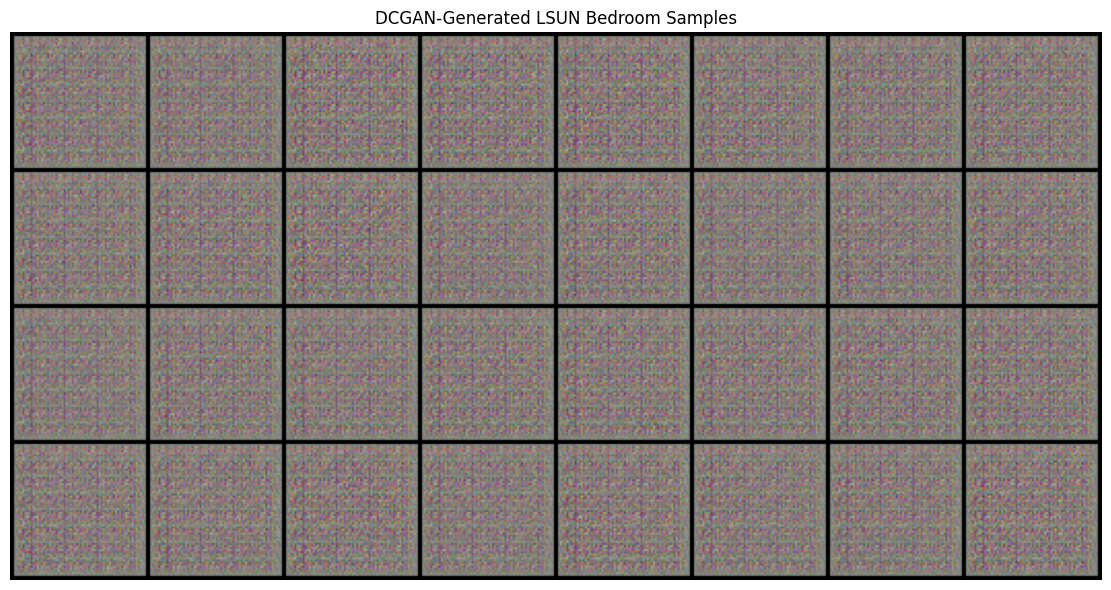

Experiment 10 completed
LSUN Bedroom images used for training: 512
FID-64 score: 50.8781
Output folder: /content/Deeplearning/outputs/experiment_10


In [ ]:
from pathlib import Path
import gc
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchmetrics.image.fid import FrechetInceptionDistance
from torchvision import transforms
from torchvision.utils import make_grid


try:
    import tensorflow as tf

    tf.keras.backend.clear_session()
except Exception:
    pass
gc.collect()

root = Path("/content/Deeplearning") if Path("/content").exists() else Path(__file__).resolve().parents[1]
dataset_dir = root / "datasets" / "lsun_bedrooms_subset"
output_dir = root / "outputs" / "experiment_10"
output_dir.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
latent_size = 100


class ImageDirectoryDataset(Dataset):
    def __init__(self, folder):
        self.paths = sorted(folder.glob("*.jpg"))
        self.transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize([0.5] * 3, [0.5] * 3)])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        return self.transform(Image.open(self.paths[index]).convert("RGB"))


class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.ConvTranspose2d(latent_size, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Tanh(),
        )

    def forward(self, noise):
        return self.layers(noise)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2),
            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2),
            nn.Conv2d(512, 1, 4, 1, 0, bias=False),
            nn.Sigmoid(),
        )

    def forward(self, images):
        return self.layers(images).view(-1)


def initialize(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight.data, 0.0, 0.02)
    if isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight.data, 1.0, 0.02)
        nn.init.constant_(module.bias.data, 0)


dataset = ImageDirectoryDataset(dataset_dir)
loader = DataLoader(dataset, batch_size=64, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())
generator = Generator().to(device)
discriminator = Discriminator().to(device)
generator.apply(initialize)
discriminator.apply(initialize)
criterion = nn.BCELoss()
generator_optimizer = torch.optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
discriminator_optimizer = torch.optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))
history_rows = []

for epoch in range(4):
    generator_loss_total = 0.0
    discriminator_loss_total = 0.0
    batches = 0
    for real_images in loader:
        real_images = real_images.to(device)
        batch_size = len(real_images)
        real_labels = torch.ones(batch_size, device=device)
        fake_labels = torch.zeros(batch_size, device=device)
        discriminator_optimizer.zero_grad()
        real_loss = criterion(discriminator(real_images), real_labels)
        noise = torch.randn(batch_size, latent_size, 1, 1, device=device)
        fake_images = generator(noise)
        fake_loss = criterion(discriminator(fake_images.detach()), fake_labels)
        discriminator_loss = real_loss + fake_loss
        discriminator_loss.backward()
        discriminator_optimizer.step()
        generator_optimizer.zero_grad()
        generator_loss = criterion(discriminator(fake_images), real_labels)
        generator_loss.backward()
        generator_optimizer.step()
        generator_loss_total += float(generator_loss.item())
        discriminator_loss_total += float(discriminator_loss.item())
        batches += 1
    row = {
        "epoch": epoch + 1,
        "generator_loss": generator_loss_total / batches,
        "discriminator_loss": discriminator_loss_total / batches,
    }
    history_rows.append(row)
    print(row)

history = pd.DataFrame(history_rows)
history.to_csv(output_dir / "gan_training_history.csv", index=False)
torch.save(generator.state_dict(), output_dir / "lsun_generator.pt")
torch.save(discriminator.state_dict(), output_dir / "lsun_discriminator.pt")

generator.eval()
fixed_noise = torch.randn(32, latent_size, 1, 1, device=device)
with torch.no_grad():
    generated_samples = generator(fixed_noise)
grid = make_grid(generated_samples, nrow=8, normalize=True, value_range=(-1, 1))
figure, axis = plt.subplots(figsize=(12, 6))
axis.imshow(grid.permute(1, 2, 0).cpu())
axis.set_title("DCGAN-Generated LSUN Bedroom Samples")
axis.axis("off")
figure.tight_layout()
figure.savefig(output_dir / "generated_lsun_bedrooms.png", dpi=180, bbox_inches="tight")
plt.show()

fid = FrechetInceptionDistance(feature=64, normalize=True).to(device)
evaluated_images = 0
with torch.no_grad():
    for real_images in loader:
        real_images = real_images.to(device)
        batch_size = len(real_images)
        fake_images = generator(torch.randn(batch_size, latent_size, 1, 1, device=device))
        fid.update((real_images + 1) / 2, real=True)
        fid.update((fake_images + 1) / 2, real=False)
        evaluated_images += batch_size
        if evaluated_images >= 256:
            break
fid_score = float(fid.compute().item())
pd.DataFrame([{"metric": "FID-64", "score": fid_score, "real_images": evaluated_images, "generated_images": evaluated_images}]).to_csv(output_dir / "gan_fid_score.csv", index=False)

generator = generator.to("cpu")
discriminator = discriminator.to("cpu")
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Experiment 10 completed")
print(f"LSUN Bedroom images used for training: {len(dataset)}")
print(f"FID-64 score: {fid_score:.4f}")
print(f"Output folder: {output_dir}")


## Output check

Confirm that this experiment saved its results before moving on.

In [ ]:
from pathlib import Path
output_dir = Path('/content/Deeplearning/outputs/experiment_10')
files = sorted(path for path in output_dir.rglob('*') if path.is_file())
assert files, f'No outputs found in {output_dir}; run the experiment cell first.'
print(f'{len(files)} output files saved in {output_dir}')
for path in files:
    print(path.relative_to(output_dir))
